# №14 зертханалық жұмыс
## Үйретілген модельді сақтау және жүктеу, эксперименттерді қадағалау, ML-модельдерді қолданысқа енгізу және мониторинг.

Барлық бақылау жасанды. Конвейерді үйретіп, сақтаймыз, жергілікті MLflow журналын қайта оқимыз, жергілікті TCP/HTTP тексеруін іске қосып, жұмыс терезелерін салыстырамыз. Файлдар `lab14_artifacts` бумасында жасалады. HTTP тексеруі үшін ядро ортасы 127.0.0.1 мекенжайына қосылуға рұқсат беруі керек.

### Орта және келісімшарт

Модель нұсқасын, үш сандық белгіні, олардың ауқымдарын және 0,5 ықтималдық шегін бекітеміз.

In [1]:
import argparse
from contextlib import closing
from hashlib import sha256
from http.client import HTTPConnection
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer
from importlib.metadata import version
import io
import json
import math
import os
from pathlib import Path
import platform
import threading
from urllib.parse import urlsplit
from urllib.request import url2pathname

import joblib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

ROOT = Path.cwd() / "lab14_artifacts"
FIGURES = ROOT / "figures"
DEFAULT_ARTIFACTS = ROOT / "run"
MODEL_VERSION = "1.0.0"
SCHEMA_VERSION = 1
THRESHOLD = .5
PSI_LIMIT = .2
CUTPOINTS = [60, 66, 72, 78, 84]
FEATURE_SCHEMA = [{"name": "temperature_c", "type": "number", "min": 0, "max": 150},
                  {"name": "vibration_mm_s", "type": "number", "min": 0, "max": 20},
                  {"name": "load_ratio", "type": "number", "min": 0, "max": 1}]
FEATURES = [item["name"] for item in FEATURE_SCHEMA]
MODEL_FILE = "model.joblib"
MANIFEST_FILE = "manifest.json"
MAX_HTTP_BYTES = 4096
PACKAGES = ("numpy", "pandas", "scikit-learn", "joblib")
THREAD_ENVIRONMENT = ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
                      "BLIS_NUM_THREADS", "NUMEXPR_NUM_THREADS")
plt.rcParams["font.family"] = "DejaVu Sans"


from IPython.display import Image, display

run_dir = DEFAULT_ARTIFACTS.resolve()
run_dir.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
print({name: version(name) for name in PACKAGES})


{'numpy': '2.5.4', 'pandas': '3.0.1', 'scikit-learn': '1.9.1', 'joblib': '1.6.0'}


### 1–3-қадамдар. Синтетика және алдын ала берілген конвейер

Тәуелсіз бөліктер: train 800, validation/reference 300 және жабық test 300. Қолданысқа енгізу үшін Logistic алдын ала жарияланған. DummyPrior бағдар ретінде қызмет етеді. Екі модель метрикалары ортақ бөліктерде есептеледі.

In [2]:
def synthetic_equipment(n, seed, shift_c=0):
    rng = np.random.default_rng(seed)
    temperature = rng.normal(70 + shift_c, 6, n)
    vibration = np.clip(rng.normal(2.5, .6, n), 0, 20)
    load = rng.uniform(.35, .95, n)
    logits = -1.35 + .11 * (temperature - 70) + .9 * (vibration - 2.5) + 1.8 * (load - .65)
    p = 1 / (1 + np.exp(-logits))
    return pd.DataFrame({"event_id": seed * 1000 + np.arange(n), "temperature_c": temperature,
                         "vibration_mm_s": vibration, "load_ratio": load, "failure": rng.binomial(1, p)})


def make_experiment_data():
    return {"train": synthetic_equipment(800, 2026), "reference": synthetic_equipment(300, 2027),
            "test": synthetic_equipment(300, 2028)}


def runtime_versions():
    return {"Python": platform.python_version(), **{name: version(name) for name in PACKAGES}}


def positive_probability(model, features):
    column = int(np.flatnonzero(model.classes_ == 1)[0])
    return model.predict_proba(features)[:, column]


def quality(y, probability):
    decisions = (probability >= THRESHOLD).astype(int)
    return {"accuracy": float(accuracy_score(y, decisions)), "roc_auc": float(roc_auc_score(y, probability)),
            "f1_positive": float(f1_score(y, decisions, pos_label=1, zero_division=0))}


def fit_experiment(data):
    train = data["train"]
    models = {"DummyPrior": DummyClassifier(strategy="prior"),
              "Logistic": make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=1000, random_state=2026))}
    with threadpool_limits(limits=1):
        for model in models.values():
            model.fit(train[FEATURES], train["failure"])
        reference = data["reference"]
        offline_test = data["test"]
        rows, test_probabilities = [], {}
        for name, model in models.items():
            ref_p = positive_probability(model, reference[FEATURES])
            test_p = positive_probability(model, offline_test[FEATURES])
            rows.append({"model": name, "reference": quality(reference["failure"], ref_p),
                         "test": quality(offline_test["failure"], test_p)})
            test_probabilities[name] = test_p.tolist()
    summary = {"deployment_model": "Logistic", "deployment_choice": "predeclared before metrics",
               "rows": rows, "test_event_ids": offline_test["event_id"].tolist(),
               "test_labels": offline_test["failure"].tolist(), "test_probabilities": test_probabilities}
    print("Офлайн салыстыру", rows)
    return models, summary


data = make_experiment_data()
models, offline = fit_experiment(data)
print("Число положительных событий", {name: int(frame["failure"].sum()) for name, frame in data.items()})


Офлайн салыстыру [{'model': 'DummyPrior', 'reference': {'accuracy': 0.7133333333333334, 'roc_auc': 0.5, 'f1_positive': 0.0}, 'test': {'accuracy': 0.74, 'roc_auc': 0.5, 'f1_positive': 0.0}}, {'model': 'Logistic', 'reference': {'accuracy': 0.7433333333333333, 'roc_auc': 0.7655944359921756, 'f1_positive': 0.35294117647058826}, 'test': {'accuracy': 0.7666666666666667, 'roc_auc': 0.7032802032802032, 'f1_positive': 0.33962264150943394}}]
Число положительных событий {'train': 182, 'reference': 86, 'test': 78}


### 4-қадам. Жазу, сенімді жүктеу және тексеру

`joblib` сенімді шығу тегін талап етеді. Жаттығуда күтілетін манифест SHA-256 мәнін сол бақыланатын іске қосу береді. Десериализацияға дейін манифесті, келісімшартты, нұсқаларды және модель байттарын салыстырамыз. 300 жолда `predict_proba` әдісінің екі бағанын салыстырамыз. Өзгертілген байтты бөлек көшірмеде тексереміз.

In [3]:
def save_bundle(model, bundle):
    bundle.mkdir(parents=True, exist_ok=True)
    pending_model = bundle / (MODEL_FILE + ".pending")
    pending_manifest = bundle / (MANIFEST_FILE + ".pending")
    joblib.dump(model, pending_model, compress=3)
    serialized = pending_model.read_bytes()
    manifest = {"model_version": MODEL_VERSION, "input_schema_version": SCHEMA_VERSION,
                "artifact_file": MODEL_FILE, "artifact_bytes": len(serialized),
                "artifact_sha256": sha256(serialized).hexdigest(), "feature_schema": FEATURE_SCHEMA,
                "decision_threshold": THRESHOLD, "positive_class": 1, "runtime": runtime_versions()}
    encoded = json.dumps(manifest, ensure_ascii=False, sort_keys=True, indent=2, allow_nan=False).encode("utf-8")
    pending_manifest.write_bytes(encoded)
    pending_model.replace(bundle / MODEL_FILE)
    pending_manifest.replace(bundle / MANIFEST_FILE)
    return manifest, sha256(encoded).hexdigest()


def load_verified(bundle, trusted_manifest_sha256):
    # Күтілетін манифест хеші сенімді арнадан алынуы керек.
    raw_manifest = (bundle / MANIFEST_FILE).read_bytes()
    if sha256(raw_manifest).hexdigest() != trusted_manifest_sha256:
        raise ValueError("Манифестің SHA-256 мәні сәйкес емес")
    manifest = json.loads(raw_manifest)
    expected = {"model_version": MODEL_VERSION, "input_schema_version": SCHEMA_VERSION,
                "artifact_file": MODEL_FILE, "feature_schema": FEATURE_SCHEMA,
                "decision_threshold": THRESHOLD, "positive_class": 1}
    if any(manifest.get(key) != value for key, value in expected.items()):
        raise ValueError("Қолдау көрсетілмейтін модель келісімшарты")
    if manifest.get("runtime") != runtime_versions():
        raise ValueError("Модельдің орындау ортасының нұсқалары бұл ортаға сәйкес емес")
    serialized = (bundle / MODEL_FILE).read_bytes()
    if len(serialized) != manifest["artifact_bytes"] or sha256(serialized).hexdigest() != manifest["artifact_sha256"]:
        raise ValueError("Модельдің SHA-256 мәні немесе ұзындығы сәйкес емес")
    # Сенімді өндірушіден алынған, тексерілген сол байттарды десериализациялау.
    return joblib.load(io.BytesIO(serialized)), manifest


def verify_reload(model, test_frame, bundle, run_dir):
    manifest, pin = save_bundle(model, bundle)
    loaded, read_manifest = load_verified(bundle, pin)
    assert manifest == read_manifest
    with threadpool_limits(limits=1):
        before = model.predict_proba(test_frame[FEATURES])
        after = loaded.predict_proba(test_frame[FEATURES])
    np.testing.assert_array_equal(before, after)
    tampered = run_dir / "tampered"
    tampered.mkdir(parents=True, exist_ok=True)
    (tampered / MANIFEST_FILE).write_bytes((bundle / MANIFEST_FILE).read_bytes())
    damaged = bytearray((bundle / MODEL_FILE).read_bytes())
    damaged[len(damaged) // 2] ^= 1
    (tampered / MODEL_FILE).write_bytes(damaged)
    try:
        load_verified(tampered, pin)
    except ValueError as exc:
        if "Модельдің SHA-256" not in str(exc):
            raise
        rejection = str(exc)
    else:
        raise AssertionError("Өзгертілген байттар қабылданды")
    print("Қайта жүктеудегі ең үлкен |айырма|", float(np.max(abs(before - after))), "өзгертілген:", rejection)
    evidence = {"manifest": manifest, "manifest_sha256": pin, "predict_proba_equal": True,
                "max_abs_predict_proba_difference": float(np.max(abs(before - after))),
                "checked_probability_shape": list(after.shape), "corruption_rejected": True,
                "corruption_error": rejection}
    return loaded, evidence, before[:, 1], after[:, 1]


bundle = run_dir / "bundle"
model, bundle_evidence, before, after = verify_reload(models["Logistic"], data["test"], bundle, run_dir)
print("SHA-256 манифеста", bundle_evidence["manifest_sha256"])


Қайта жүктеудегі ең үлкен |айырма| 0.0 өзгертілген: Модельдің SHA-256 мәні немесе ұзындығы сәйкес емес
SHA-256 манифеста 965b78c9a70f6922c86fd458c1dd04a35317d10b38372fa5c9191196889e27fb


### 5-қадам. Нақты жергілікті MLflow

File URI клиентке тікелей беріледі. Екі іске қосуды, параметрлерді, reference метрикаларын және Logistic артефактілерін сақтаймыз. Жазбаларды қайта оқып, артефакт көшірмелерінің SHA-256 мәндерін салыстырамыз.

In [4]:
def track_experiments(offline, bundle, run_dir):
    os.environ["MLFLOW_DISABLE_TELEMETRY"] = "true"
    from mlflow.tracking import MlflowClient

    tracking_root = (run_dir / "mlruns").resolve()
    artifact_root = (run_dir / "mlflow_artifacts").resolve()
    tracking_root.mkdir(parents=True, exist_ok=True)
    artifact_root.mkdir(parents=True, exist_ok=True)
    tracking_uri = tracking_root.as_uri()
    client = MlflowClient(tracking_uri=tracking_uri)
    experiment_name = "lab14-synthetic-equipment"
    experiment = client.get_experiment_by_name(experiment_name)
    experiment_id = (experiment.experiment_id if experiment else
                     client.create_experiment(experiment_name, artifact_location=artifact_root.as_uri()))
    records = []
    for row in offline["rows"]:
        name = row["model"]
        run = client.create_run(experiment_id, run_name=name,
                                tags={"data_kind": "synthetic", "metric_split": "reference"})
        run_id = run.info.run_id
        parameters = {"model": name, "train_seed": "2026", "train_size": "800", "threshold": str(THRESHOLD)}
        parameters.update({"C": "1", "max_iter": "1000"} if name == "Logistic" else {"strategy": "prior"})
        metrics = {f"reference_{key}": value for key, value in row["reference"].items()}
        try:
            for key, value in parameters.items():
                client.log_param(run_id, key, value)
            for key, value in metrics.items():
                client.log_metric(run_id, key, value)
            if name == "Logistic":
                for file in (MODEL_FILE, MANIFEST_FILE):
                    client.log_artifact(run_id, str(bundle / file), artifact_path="bundle")
        except Exception:
            client.set_terminated(run_id, status="FAILED")
            raise
        client.set_terminated(run_id, status="FINISHED")
        stored = client.get_run(run_id)
        stored_files = sorted(item.path for item in client.list_artifacts(run_id, "bundle"))
        expected_files = [f"bundle/{MANIFEST_FILE}", f"bundle/{MODEL_FILE}"] if name == "Logistic" else []
        assert stored.info.status == "FINISHED" and stored.data.params == parameters
        assert stored.data.metrics == metrics and stored_files == expected_files
        artifact_digests = {}
        if name == "Logistic":
            uri = urlsplit(stored.info.artifact_uri)
            assert uri.scheme == "file" and uri.netloc in ("", "localhost")
            actual_root = Path(url2pathname(uri.path)).resolve()
            assert actual_root.is_relative_to(artifact_root)
            for file in (MODEL_FILE, MANIFEST_FILE):
                digest = sha256((actual_root / "bundle" / file).read_bytes()).hexdigest()
                assert digest == sha256((bundle / file).read_bytes()).hexdigest()
                artifact_digests[file] = digest
        records.append({"name": name, "run_id": run_id, "params": stored.data.params, "metrics": stored.data.metrics,
                        "status": stored.info.status, "artifacts": stored_files, "artifact_sha256": artifact_digests,
                        "artifact_uri": stored.info.artifact_uri})
    result = {"backend": "local MLflow FileStore", "tracking_uri": tracking_uri,
              "artifact_root_uri": artifact_root.as_uri(), "experiment_id": experiment_id,
              "version": version("mlflow-skinny"), "verified_runs": records}
    print("MLflow деректері сақталды", [(row["name"], row["run_id"]) for row in records])
    return result


tracking = track_experiments(offline, bundle, run_dir)


MLflow деректері сақталды [('DummyPrior', '387212723d8e41ed86bebda95c58be96'), ('Logistic', '120946a9a755458d97c722bbba351a8d')]


### 6-қадам. Нақты loopback сұраулары

Сервер 127.0.0.1 мекенжайын автоматты таңдалған портта тыңдайды. Жұмыс күйін, дұрыс болжамды, өрістер валидациясын және қате кодтарын тексереміз. Тым ұзын сұрау үшін мәлімделген өлшемі бар тақырыпты береміз. Тексерулерден кейін сервер жабылады.

In [5]:
def unique_json_object(pairs):
    result = {}
    for key, value in pairs:
        if key in result:
            raise ValueError("Қайталанатын JSON өрісі")
        result[key] = value
    return result


def parse_features(raw):
    values = json.loads(raw, object_pairs_hook=unique_json_object)
    if not isinstance(values, dict) or set(values) != set(FEATURES):
        raise ValueError("Сұлбаның дәл үш өрісі күтіледі")
    for field in FEATURE_SCHEMA:
        value = values[field["name"]]
        if (type(value) not in (int, float) or not math.isfinite(value)
                or not field["min"] <= value <= field["max"]):
            raise ValueError(f"Мына өріс үшін жарамсыз сан: {field['name']}")
    return pd.DataFrame([[values[name] for name in FEATURES]], columns=FEATURES)


def make_loopback_server(model, manifest, port=0):
    class Handler(BaseHTTPRequestHandler):
        def setup(self):
            super().setup()
            self.connection.settimeout(5)

        def log_message(self, *args):
            pass

        def reply(self, code, payload, allow=None):
            encoded = json.dumps(payload, ensure_ascii=False, allow_nan=False).encode("utf-8")
            self.send_response(code)
            self.send_header("Content-Type", "application/json; charset=utf-8")
            self.send_header("Content-Length", str(len(encoded)))
            if allow is not None:
                self.send_header("Allow", allow)
            self.end_headers()
            self.wfile.write(encoded)

        def do_GET(self):
            if self.path == "/health":
                self.reply(200, {"ready": True, "model_version": manifest["model_version"],
                                 "input_schema_version": manifest["input_schema_version"]})
            elif self.path == "/predict":
                self.reply(405, {"error": "POST қолданыңыз"}, allow="POST")
            else:
                self.reply(404, {"error": "Белгісіз бағыт"})

        def do_POST(self):
            if self.path != "/predict":
                if self.path == "/health":
                    self.reply(405, {"error": "GET қолданыңыз"}, allow="GET")
                else:
                    self.reply(404, {"error": "Белгісіз бағыт"})
                return
            if self.headers.get_content_type() != "application/json":
                self.reply(415, {"error": "application/json күтіледі"})
                return
            try:
                length = int(self.headers.get("Content-Length", "0"))
                if length <= 0:
                    raise ValueError("Сұрау денесі бос")
                if length > MAX_HTTP_BYTES:
                    self.reply(413, {"error": "Сұрау денесі тым үлкен"})
                    return
                features = parse_features(self.rfile.read(length))
            except (ValueError, OverflowError) as exc:
                self.reply(400, {"error": str(exc)})
                return
            probability = float(positive_probability(model, features)[0])
            self.reply(200, {"failure_probability": probability, "predicted_failure": int(probability >= THRESHOLD),
                             "model_version": manifest["model_version"], "decision_threshold": THRESHOLD,
                             "input_schema_version": manifest["input_schema_version"]})

    return ThreadingHTTPServer(("127.0.0.1", port), Handler)


def run_http_checks(model, manifest, sample):
    valid = {name: float(sample.iloc[0][name]) for name in reversed(FEATURES)}
    valid_bytes = json.dumps(valid).encode("utf-8")
    cases = [("health", "GET", "/health", None, None, 200),
             ("prediction", "POST", "/predict", valid_bytes, "application/json", 200),
             ("broken_json", "POST", "/predict", b"{", "application/json", 400),
             ("missing_field", "POST", "/predict", b"{}", "application/json", 400),
             ("boolean_feature", "POST", "/predict",
              json.dumps({**valid, "load_ratio": True}).encode(), "application/json", 400),
             ("out_of_range", "POST", "/predict",
              json.dumps({**valid, "load_ratio": 1.2}).encode(), "application/json", 400),
             ("duplicate_field", "POST", "/predict",
              valid_bytes[:-1] + b', "load_ratio": 0.5}', "application/json", 400),
             ("unknown_route", "GET", "/unknown", None, None, 404),
             ("wrong_method", "GET", "/predict", None, None, 405),
             ("oversized", "POST", "/predict", b"", "application/json", 413),
             ("wrong_content_type", "POST", "/predict", b"", "text/plain", 415)]
    statuses, bodies = {}, {}
    with make_loopback_server(model, manifest) as server:
        thread = threading.Thread(target=server.serve_forever, kwargs={"poll_interval": .05}, daemon=True)
        thread.start()
        try:
            for name, method, path, content, mime, expected in cases:
                headers = {"Content-Type": mime} if mime else {}
                if name == "oversized":
                    # Оқылмайтын денені жібермей, ерте қабылдамауды тексеру.
                    headers["Content-Length"] = str(MAX_HTTP_BYTES + 1)
                with closing(HTTPConnection("127.0.0.1", server.server_port, timeout=4)) as connection:
                    connection.request(method, path, body=content, headers=headers)
                    with connection.getresponse() as response:
                        statuses[name] = response.status
                        assert response.status == expected, (name, response.status, expected)
                        assert response.headers.get_content_type() == "application/json"
                        bodies[name] = json.load(response)
                        if name == "wrong_method":
                            assert response.headers["Allow"] == "POST"
        finally:
            server.shutdown()
            thread.join(timeout=5)
            assert not thread.is_alive()
    assert bodies["health"]["ready"] and bodies["health"]["model_version"] == MODEL_VERSION
    expected = float(positive_probability(model, sample[FEATURES])[0])
    measured = bodies["prediction"]["failure_probability"]
    np.testing.assert_allclose(measured, expected, atol=1e-12, rtol=0)
    assert bodies["prediction"]["predicted_failure"] == int(expected >= THRESHOLD)
    print("Нақты loopback HTTP", statuses)
    return {"transport": "HTTP over TCP loopback", "bind_address": "127.0.0.1", "ephemeral_port": True,
            "statuses": statuses, "health": bodies["health"], "example_prediction": bodies["prediction"],
            "direct_probability": expected, "max_abs_probability_difference": abs(measured - expected),
            "server_closed": True}


http = run_http_checks(model, bundle_evidence["manifest"], data["test"].iloc[:1])
print(http["example_prediction"])


Нақты loopback HTTP {'health': 200, 'prediction': 200, 'broken_json': 400, 'missing_field': 400, 'boolean_feature': 400, 'out_of_range': 400, 'duplicate_field': 400, 'unknown_route': 404, 'wrong_method': 405, 'oversized': 413, 'wrong_content_type': 415}
{'failure_probability': 0.4372269037719336, 'predicted_failure': 0, 'model_version': '1.0.0', 'decision_threshold': 0.5, 'input_schema_version': 1}


### 7–8-қадамдар. Жұмыс терезелері және кідіру

Температура аралықтарының үлестері үшін reference қолданамыз. Шартты істен шығу формуласын сақтап, екінші терезенің орташа температурасын 9 °C-қа ығыстырамыз. Кідіру терезесінде дайын класс белгілерінің үлесі жеті күннен кейін 0-ден 1-ге өседі. Оған дейін сапа метрикалары қолжетімсіз болып қалады.

In [6]:
def temperature_counts(values):
    return np.histogram(values, bins=[-np.inf, *CUTPOINTS, np.inf])[0]


def smoothed_psi(reference_counts, window_counts):
    reference = reference_counts.astype(float) + .5
    current = window_counts.astype(float) + .5
    reference /= reference.sum()
    current /= current.sum()
    return float(np.sum((current - reference) * np.log(current / reference)))


def monitor_snapshot(name, as_of, events, probabilities, reference_counts, labels=None):
    counts = temperature_counts(events["temperature_c"])
    psi = smoothed_psi(reference_counts, counts)
    measured_quality = None
    matched_count = 0
    if labels is not None:
        visible = labels.loc[labels["available_on"] <= as_of, ["event_id", "failure"]]
        joined = events[["event_id"]].merge(visible, on="event_id", how="left", sort=False, validate="one_to_one")
        visible_mask = joined["failure"].notna().to_numpy()
        matched_count = int(visible_mask.sum())
        if matched_count == len(events):
            measured_quality = quality(joined["failure"].astype(int), probabilities)
    return {"window": name, "as_of": as_of, "n": len(events), "temperature_counts": counts.tolist(),
            "temperature_mean": float(events["temperature_c"].mean()), "temperature_psi": psi,
            "psi_alert": psi >= PSI_LIMIT, "mean_probability": float(np.mean(probabilities)),
            "predicted_positive_rate": float(np.mean(probabilities >= THRESHOLD)),
            "labels_ready": matched_count, "label_coverage": matched_count / len(events),
            "quality": measured_quality}


def simulate_monitoring(model, reference):
    reference_counts = temperature_counts(reference["temperature_c"])
    specs = [("stable", 2029, 0, "2026-02-01", "2026-02-01"),
             ("shifted", 2030, 9, "2026-02-08", "2026-02-08"),
             ("delayed", 2031, 0, "2026-02-15", "2026-02-22")]
    rows = []
    with threadpool_limits(limits=1):
        for name, seed, shift, time, ready in specs:
            complete = synthetic_equipment(250, seed, shift)
            events = complete.drop(columns="failure")
            probabilities = positive_probability(model, events[FEATURES])
            labels = complete[["event_id", "failure"]].assign(available_on=ready)
            labels = labels.sample(frac=1, random_state=2032)
            if name == "delayed":
                rows.append(monitor_snapshot("delayed_t0", time, events, probabilities, reference_counts))
                rows.append(monitor_snapshot("delayed_t7", ready, events, probabilities, reference_counts, labels))
            else:
                rows.append(monitor_snapshot(name, time, events, probabilities, reference_counts, labels))
    assert rows[2]["labels_ready"] == 0 and rows[2]["quality"] is None
    assert rows[3]["labels_ready"] == 250 and rows[3]["quality"] is not None
    assert rows[2]["temperature_psi"] == rows[3]["temperature_psi"]
    print("Мониторинг терезелері", rows)
    return {"temperature_cutpoints_c": CUTPOINTS, "histogram_smoothing_per_bin": .5,
            "educational_psi_alert_threshold": PSI_LIMIT, "reference_n": len(reference),
            "reference_temperature_counts": reference_counts.tolist(),
            "reference_temperature_mean": float(reference["temperature_c"].mean()),
            "label_join_key": "event_id", "minimum_label_coverage_for_reported_quality": 1,
            "window_specs": [{"name": name, "seed": seed, "temperature_shift_c": shift,
                              "event_date": time, "labels_available_on": ready}
                             for name, seed, shift, time, ready in specs], "rows": rows}


monitoring = simulate_monitoring(model, data["reference"])


Мониторинг терезелері [{'window': 'stable', 'as_of': '2026-02-01', 'n': 250, 'temperature_counts': [16, 44, 104, 61, 23, 2], 'temperature_mean': 69.89019577655732, 'temperature_psi': 0.021262072288504897, 'psi_alert': False, 'mean_probability': 0.24239468657483632, 'predicted_positive_rate': 0.108, 'labels_ready': 250, 'label_coverage': 1.0, 'quality': {'accuracy': 0.804, 'roc_auc': 0.7438038793103448, 'f1_positive': 0.4235294117647059}}, {'window': 'shifted', 'as_of': '2026-02-08', 'n': 250, 'temperature_counts': [0, 6, 27, 90, 90, 37], 'temperature_mean': 78.24185183595124, 'temperature_psi': 1.4153218219601695, 'psi_alert': True, 'mean_probability': 0.3722103202579747, 'predicted_positive_rate': 0.26, 'labels_ready': 250, 'label_coverage': 1.0, 'quality': {'accuracy': 0.664, 'roc_auc': 0.7466276829025185, 'f1_positive': 0.4939759036144578}}, {'window': 'delayed_t0', 'as_of': '2026-02-15', 'n': 250, 'temperature_counts': [16, 51, 86, 76, 19, 2], 'temperature_mean': 69.78152994978241,

### 9-қадам. Суреттер және қорытынды

Жүктеуге дейінгі және кейінгі ықтималдықтарды салыстырыңыз. PSI оқу шегі 0,2-ден асатын жұмыс терезесін табыңыз. Сапа графигіндегі бос орынды түсіндіріңіз.

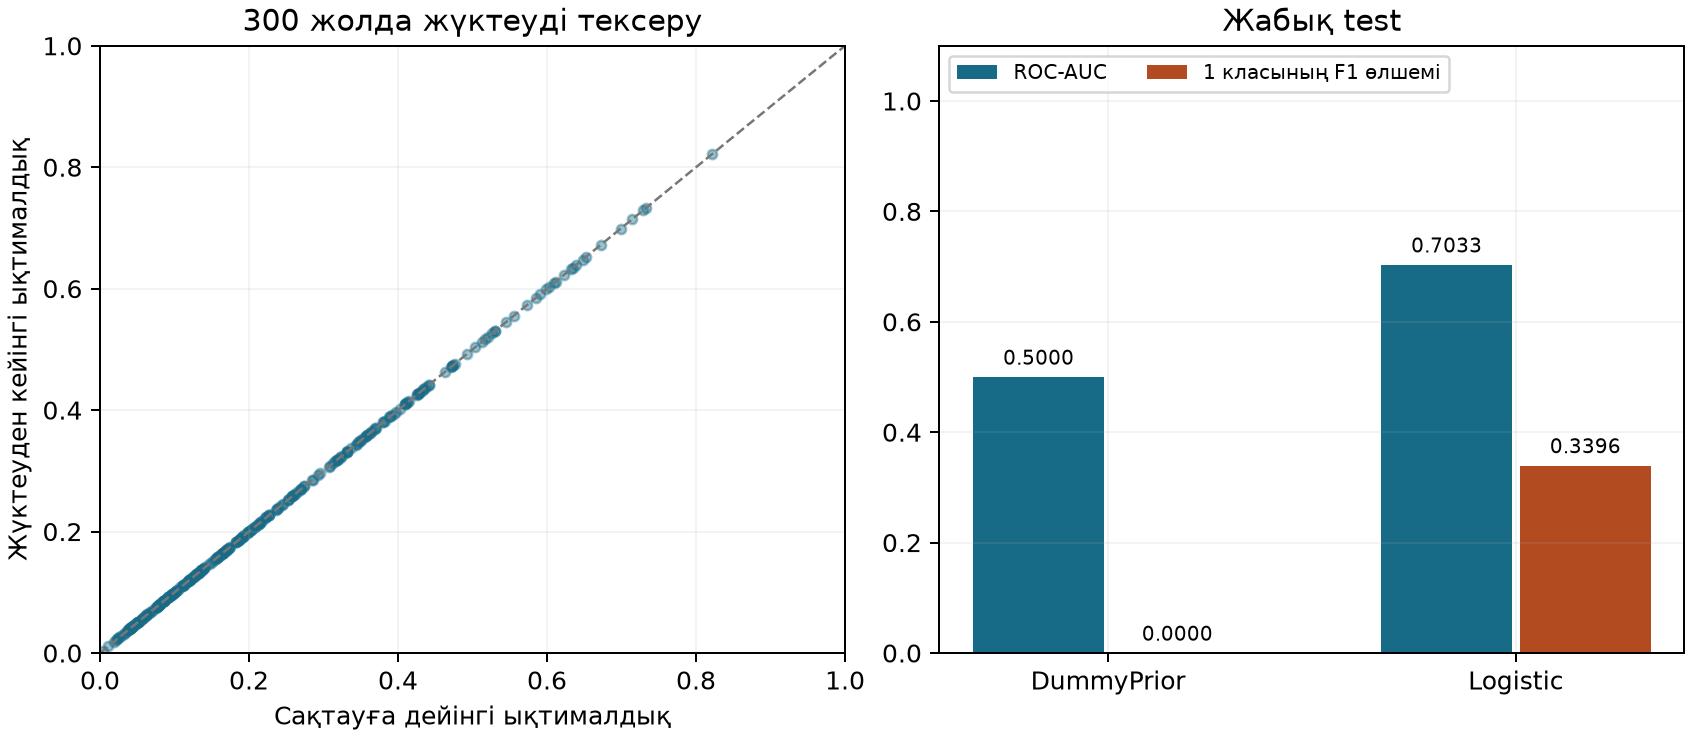

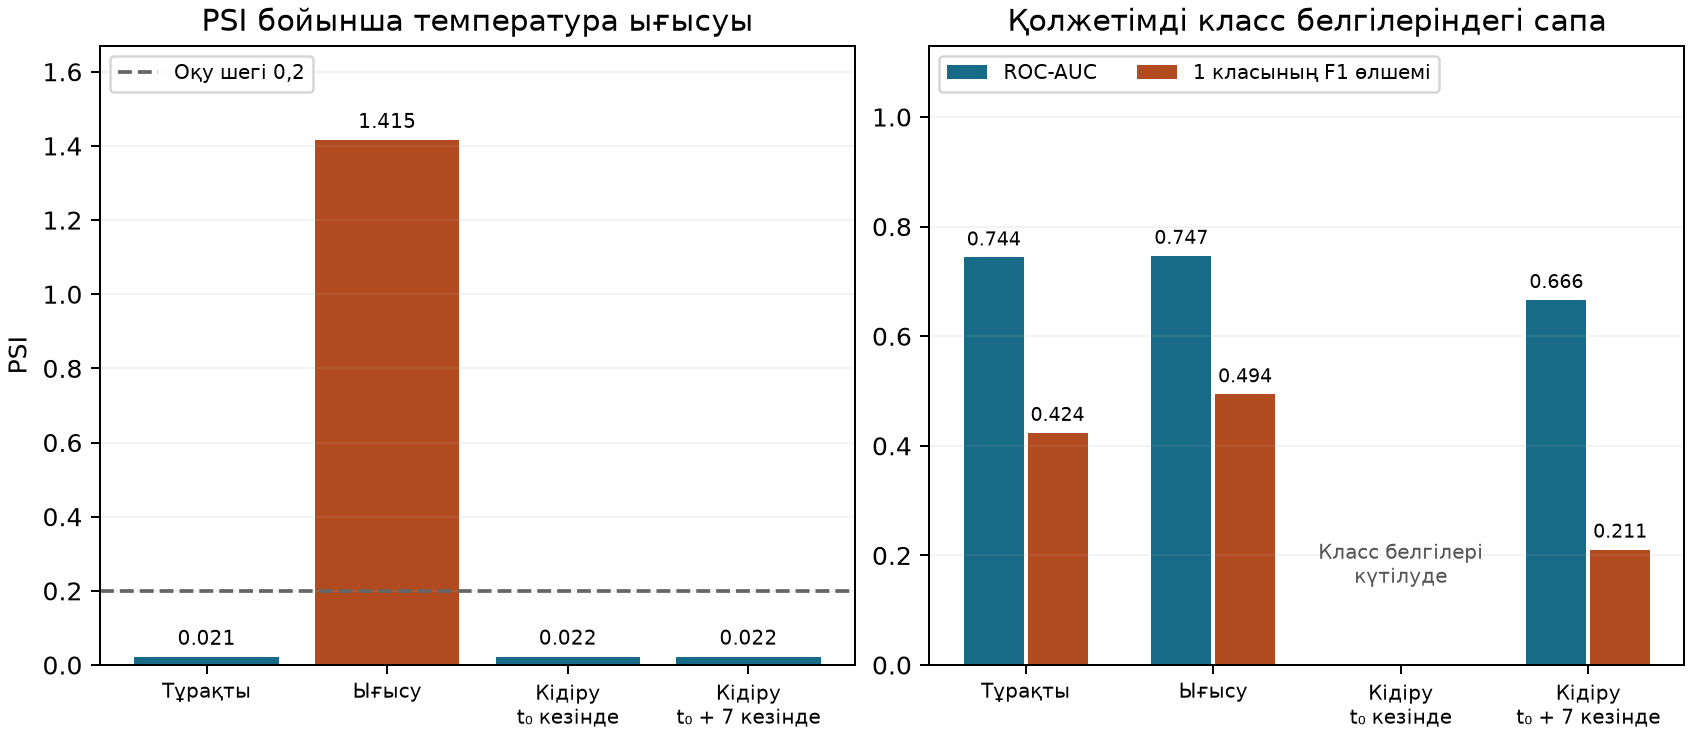

In [7]:
def plot_bundle(before, after, offline, path):
    fig, axes = plt.subplots(1, 2, figsize=(9.4, 4.1), layout="constrained")
    axes[0].plot([0, 1], [0, 1], color="#777777", linestyle="--", linewidth=1)
    axes[0].scatter(before, after, color="#176B87", alpha=.42, s=14)
    axes[0].set(title="300 жолда жүктеуді тексеру", xlabel="Сақтауға дейінгі ықтималдық",
                ylabel="Жүктеуден кейінгі ықтималдық", xlim=(0, 1), ylim=(0, 1))
    x = np.arange(len(offline["rows"]))
    for offset, metric, color, label in ((-.17, "roc_auc", "#176B87", "ROC-AUC"),
                                         (.17, "f1_positive", "#B34B20", "1 класының F1 өлшемі")):
        bars = axes[1].bar(x + offset, [row["test"][metric] for row in offline["rows"]], width=.32,
                           color=color, label=label)
        axes[1].bar_label(bars, fmt="%.4f", padding=3, fontsize=8)
    axes[1].set(title="Жабық test", xticks=x, xticklabels=[row["model"] for row in offline["rows"]], ylim=(0, 1.1))
    axes[1].legend(loc="upper left", ncols=2, fontsize=8)
    for ax in axes:
        ax.grid(alpha=.14)
    fig.savefig(path, dpi=180)
    plt.close(fig)


def plot_monitoring(monitoring, path):
    fig, axes = plt.subplots(1, 2, figsize=(9.4, 4.1), layout="constrained")
    rows = monitoring["rows"]
    positions = np.arange(len(rows))
    names = ["Тұрақты", "Ығысу", "Кідіру\nt₀ кезінде", "Кідіру\nt₀ + 7 кезінде"]
    psis = [row["temperature_psi"] for row in rows]
    bars = axes[0].bar(positions, psis, color=["#B34B20" if row["psi_alert"] else "#176B87" for row in rows])
    axes[0].bar_label(bars, fmt="%.3f", padding=3, fontsize=8)
    axes[0].axhline(PSI_LIMIT, linestyle="--", color="#666666", label="Оқу шегі 0,2")
    axes[0].set(title="PSI бойынша температура ығысуы", ylabel="PSI", ylim=(0, max(max(psis) * 1.18, .3)))
    axes[0].legend(fontsize=8, loc="upper left")
    visible = [(position, row["quality"]) for position, row in enumerate(rows) if row["quality"] is not None]
    for offset, metric, color, label in ((-.17, "roc_auc", "#176B87", "ROC-AUC"),
                                         (.17, "f1_positive", "#B34B20", "1 класының F1 өлшемі")):
        bars = axes[1].bar([position + offset for position, _ in visible],
                           [value[metric] for _, value in visible], width=.32, color=color, label=label)
        axes[1].bar_label(bars, fmt="%.3f", padding=3, fontsize=7.5)
    axes[1].text(2, .15, "Класс белгілері\nкүтілуде", ha="center", fontsize=8, color="#555555")
    axes[1].set(title="Қолжетімді класс белгілеріндегі сапа", ylim=(0, 1.13))
    axes[1].legend(fontsize=8, ncols=2, loc="upper left")
    for ax in axes:
        ax.set(xticks=positions, xticklabels=names)
        ax.tick_params(axis="x", labelsize=8)
        ax.grid(axis="y", alpha=.14)
    fig.savefig(path, dpi=180)
    plt.close(fig)


plot_bundle(before, after, offline, FIGURES / "ch14_05_bundle_parity.png")
plot_monitoring(monitoring, FIGURES / "ch14_06_monitoring_windows.png")
display(Image(filename=str(FIGURES / "ch14_05_bundle_parity.png")))
display(Image(filename=str(FIGURES / "ch14_06_monitoring_windows.png")))


**Жауабыңыз.** Класс белгілері алынғанға дейін PSI сигналы неліктен болуы мүмкін? Жүктеуден кейінгі бірдей болжамдар жаңа ағындағы олардың сапасы туралы неліктен ештеңе айтпайды?

_Өз қорытындыңызды жазыңыз._

### 10-қадам. Екі журнал

Сандарды, нұсқаларды және SHA-256 мәндерін `lab14_results.json` файлында сақтаймыз. Run ID, URI және эксперимент идентификаторы `lab14_tracking.json` файлында бөлек сақталады. Қайталауларды салыстыру үшін бірінші файлды қолданыңыз.

In [8]:
def save_results(data, offline, bundle_evidence, http, monitoring, tracking, path):
    result = {"data_kind": "synthetic equipment failure", "decision_threshold": THRESHOLD,
              "data_partitions": {name: {"n": len(frame), "positive": int(frame["failure"].sum()),
                                          "event_ids": frame["event_id"].tolist()}
                                  for name, frame in data.items()},
              "offline": offline, "bundle": bundle_evidence, "http": http, "monitoring": monitoring,
              "tracking": {"backend": tracking["backend"], "version": tracking["version"],
                           "verified_runs": len(tracking["verified_runs"])},
              "runtime": {**runtime_versions(), "matplotlib": version("matplotlib"),
                          "threadpoolctl": version("threadpoolctl"),
                          "thread_environment": {name: os.getenv(name) for name in THREAD_ENVIRONMENT}}}
    path.write_text(json.dumps(result, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    return result


result = save_results(data, offline, bundle_evidence, http, monitoring, tracking,
                      ROOT / "lab14_results.json")
(ROOT / "lab14_tracking.json").write_text(json.dumps(tracking, ensure_ascii=False, indent=2), encoding="utf-8")
assert bundle_evidence["predict_proba_equal"] and bundle_evidence["corruption_rejected"]
assert all(row["status"] == "FINISHED" for row in tracking["verified_runs"])
assert http["statuses"]["prediction"] == 200 and http["server_closed"]
assert monitoring["rows"][2]["quality"] is None
assert monitoring["rows"][3]["labels_ready"] == 250
print("Нәтижелер мен бөлек MLflow журналы lab14_artifacts бумасында сақталды.")


Нәтижелер мен бөлек MLflow журналы lab14_artifacts бумасында сақталды.


### Жеке нұсқа және қорғау

1. Сұраудағы өрістер ретін және артық кілтті тексеріңіз.
2. Манифесті өзгертіп, бастапқы бақылау қосындысы бойынша жүктеудің қабылданбауын тексеріңіз.
3. Екі алдын ала берілген C мәнін бөлек reference журналында салыстырыңыз.
4. Жұмыс терезелерінде екі шекара торындағы PSI мәндерін салыстырыңыз.
5. Класс белгілерінің ішінара пайда болуын модельдеп, қамту үлесін хабарлаңыз.
6. Синтетиканың екі сценарийіндегі орташа тәуекелді, іске қосылулар үлесін және сапаны салыстырыңыз.

Жергілікті рубрика 100%-ды құрайды. Деректер мен келісімшарт 15%, сақтау мен тексеру 20%, журнал 15%, HTTP 20%, мониторинг 20%, қорытынды мен нұсқа 10%. Силлабус бөлек 7 ресми балл көрсетеді.

1. Келісімшартқа қандай белгілер мен ауқымдар кіреді?
2. Шек қалай бекітіледі?
3. Күтілетін манифест SHA-256 мәні қайдан алынады?
4. joblib жүктеуіне дейін не тексеріледі?
5. MLflow-да қандай параметрлер мен метрикалар жазылған?
6. Run ID неліктен бөлек сақталады?
7. /health және /predict жауаптары қалай ерекшеленеді?
8. Reference бойынша PSI қалай құрылады?
9. Класс белгілерінің үлесі нөл болғанда қандай көрсеткіштер қолжетімді?
10. Оқиғалар мен класс белгілерін event_id бойынша неліктен біріктіру керек?